# Mission 7 — Stratégie de contenu et mesure
**TP Customer Intelligence & AI Marketing Strategy — cas NovaMarket**

**Objectif :** mesurer la performance des 45 contenus publiés, comparer canaux et formats sans confondre corrélation et causalité, et en tirer le mix éditorial du calendrier de 2 semaines.

Le prompt structuré, les 3 contenus déclinés, le calendrier éditorial et la grille de validation humaine sont dans le document **« Mission 7 — Stratégie de contenu IA »** (dossier `livrables`).

**Plan**

0. Mise en place
1. Les données
2. Calcul des KPI par contenu
3. KPI globaux vs objectif O3
4. Comparaison par canal
5. Comparaison par format
6. Croisement canal × format
7. Meilleurs et moins bons contenus
8. Corrélation n'est pas causalité
9. Scénario de réallocation du budget
10. Recommandations pour le calendrier éditorial
11. Export de `content_kpis.csv`

## 0. Mise en place

In [1]:
import os, warnings
warnings.filterwarnings('ignore', category=UserWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_NovaMarket'
except ImportError:
    BASE = os.environ.get('TP_BASE', '..')

DATA = os.path.join(BASE, 'data')
OUT = os.path.join(BASE, 'outputs')
os.makedirs(OUT, exist_ok=True)

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
COUL_CANAL = {'Instagram': '#C2185B', 'Blog': '#F9A825', 'Newsletter': '#1565C0', 'LinkedIn': '#455A64'}

## 1. Les données

In [2]:
contenus = pd.read_csv(os.path.join(DATA, 'content_performance.csv'), parse_dates=['publication_date'])
print(f"{len(contenus)} contenus publiés du {contenus['publication_date'].min():%d/%m/%Y} au {contenus['publication_date'].max():%d/%m/%Y}")
print('Contenus par canal × format :')
pd.crosstab(contenus['channel'], contenus['content_type'], margins=True, margins_name='Total')

45 contenus publiés du 01/01/2025 au 19/12/2025
Contenus par canal × format :


content_type,education,product,promotion,storytelling,Total
channel,,,,,
Blog,4,3,1,4,12
Instagram,2,3,3,7,15
LinkedIn,2,2,5,2,11
Newsletter,2,1,3,1,7
Total,10,9,12,14,45


**Attention aux petits effectifs :** certaines combinaisons canal × format ne comptent qu'**un seul contenu**, par exemple Newsletter × storytelling ou Blog × promotion. Un seul post ne permet pas de conclure.

## 2. Calcul des KPI par contenu
Formules de l'énoncé :

| KPI | Formule | Ce qu'il mesure |
|---|---|---|
| Taux d'engagement | interactions / portée × 100 | Le contenu fait-il réagir ? |
| CTR | clics / portée × 100 | Le contenu donne-t-il envie d'en savoir plus ? (la portée sert de proxy aux impressions) |
| Taux de conversion | conversions / clics × 100 | Le clic se transforme-t-il en action ? |
| CPL (coût par conversion) | coût / conversions | Combien coûte une conversion ? (proxy pédagogique) |

In [3]:
contenus['taux_engagement_pct'] = contenus['interactions'] / contenus['reach'] * 100
contenus['ctr_pct'] = contenus['clicks'] / contenus['reach'] * 100
contenus['taux_conversion_pct'] = contenus['conversions'] / contenus['clicks'] * 100
contenus['cpl_eur'] = contenus['cost_eur'] / contenus['conversions']
contenus.head().round(2)

,content_id,publication_date,channel,content_type,reach,clicks,interactions,conversions,cost_eur,taux_engagement_pct,ctr_pct,taux_conversion_pct,cpl_eur
0,POST001,2025-01-01,Instagram,promotion,10215,302,600,32,239.78,5.87,2.96,10.60,7.49
1,POST002,2025-01-09,LinkedIn,promotion,7897,181,1120,16,408.92,14.18,2.29,8.84,25.56
2,POST003,2025-01-17,Instagram,education,28519,518,3982,16,309.19,13.96,1.82,3.09,19.32
3,POST004,2025-01-25,Instagram,product,14312,409,797,6,271.87,5.57,2.86,1.47,45.31
4,POST005,2025-02-02,Instagram,storytelling,5751,491,628,40,553.77,10.92,8.54,8.15,13.84


## 3. KPI globaux vs objectif O3
Pour agréger, on **additionne d'abord** les volumes (portée, clics, conversions, coût) **puis on calcule** les taux. Faire la moyenne des taux de chaque post donnerait le même poids à un post vu 1 300 fois qu'à un post vu 29 000 fois.

In [4]:
def kpi(groupe):
    s = groupe[['reach', 'clicks', 'interactions', 'conversions', 'cost_eur']].sum()
    return pd.Series({
        'nb_contenus': len(groupe), 'portee': s['reach'], 'conversions': s['conversions'], 'cout_eur': s['cost_eur'],
        'taux_engagement_pct': s['interactions'] / s['reach'] * 100,
        'ctr_pct': s['clicks'] / s['reach'] * 100,
        'taux_conversion_pct': s['conversions'] / s['clicks'] * 100,
        'cpl_eur': s['cost_eur'] / s['conversions'],
    })

global_kpi = kpi(contenus)
display(global_kpi.round(2).to_frame('valeur'))
print(f"Objectif O3 (note de cadrage) : conversion 6,5 % → 8 % et CPL 7,35 € → 6,50 €")

,valeur
nb_contenus,45.00
portee,647353.00
conversions,2738.00
cout_eur,20134.14
taux_engagement_pct,9.86
ctr_pct,6.49
taux_conversion_pct,6.52
cpl_eur,7.35


Objectif O3 (note de cadrage) : conversion 6,5 % → 8 % et CPL 7,35 € → 6,50 €


## 4. Comparaison par canal

In [5]:
par_canal = contenus.groupby('channel').apply(kpi, include_groups=False)
par_canal['part_conversions_%'] = par_canal['conversions'] / par_canal['conversions'].sum() * 100
par_canal['part_budget_%'] = par_canal['cout_eur'] / par_canal['cout_eur'].sum() * 100
par_canal = par_canal.sort_values('cpl_eur')
par_canal.round(2)

,nb_contenus,portee,conversions,cout_eur,taux_engagement_pct,ctr_pct,taux_conversion_pct,cpl_eur,part_conversions_%,part_budget_%
channel,,,,,,,,,,
Instagram,15.0,249450.0,1275.0,6227.50,9.44,6.41,7.97,4.88,46.57,30.93
Blog,12.0,163850.0,792.0,5407.80,11.46,8.54,5.66,6.83,28.93,26.86
Newsletter,7.0,79202.0,377.0,3620.18,9.85,7.14,6.67,9.60,13.77,17.98
LinkedIn,11.0,154851.0,294.0,4878.66,8.84,4.12,4.61,16.59,10.74,24.23


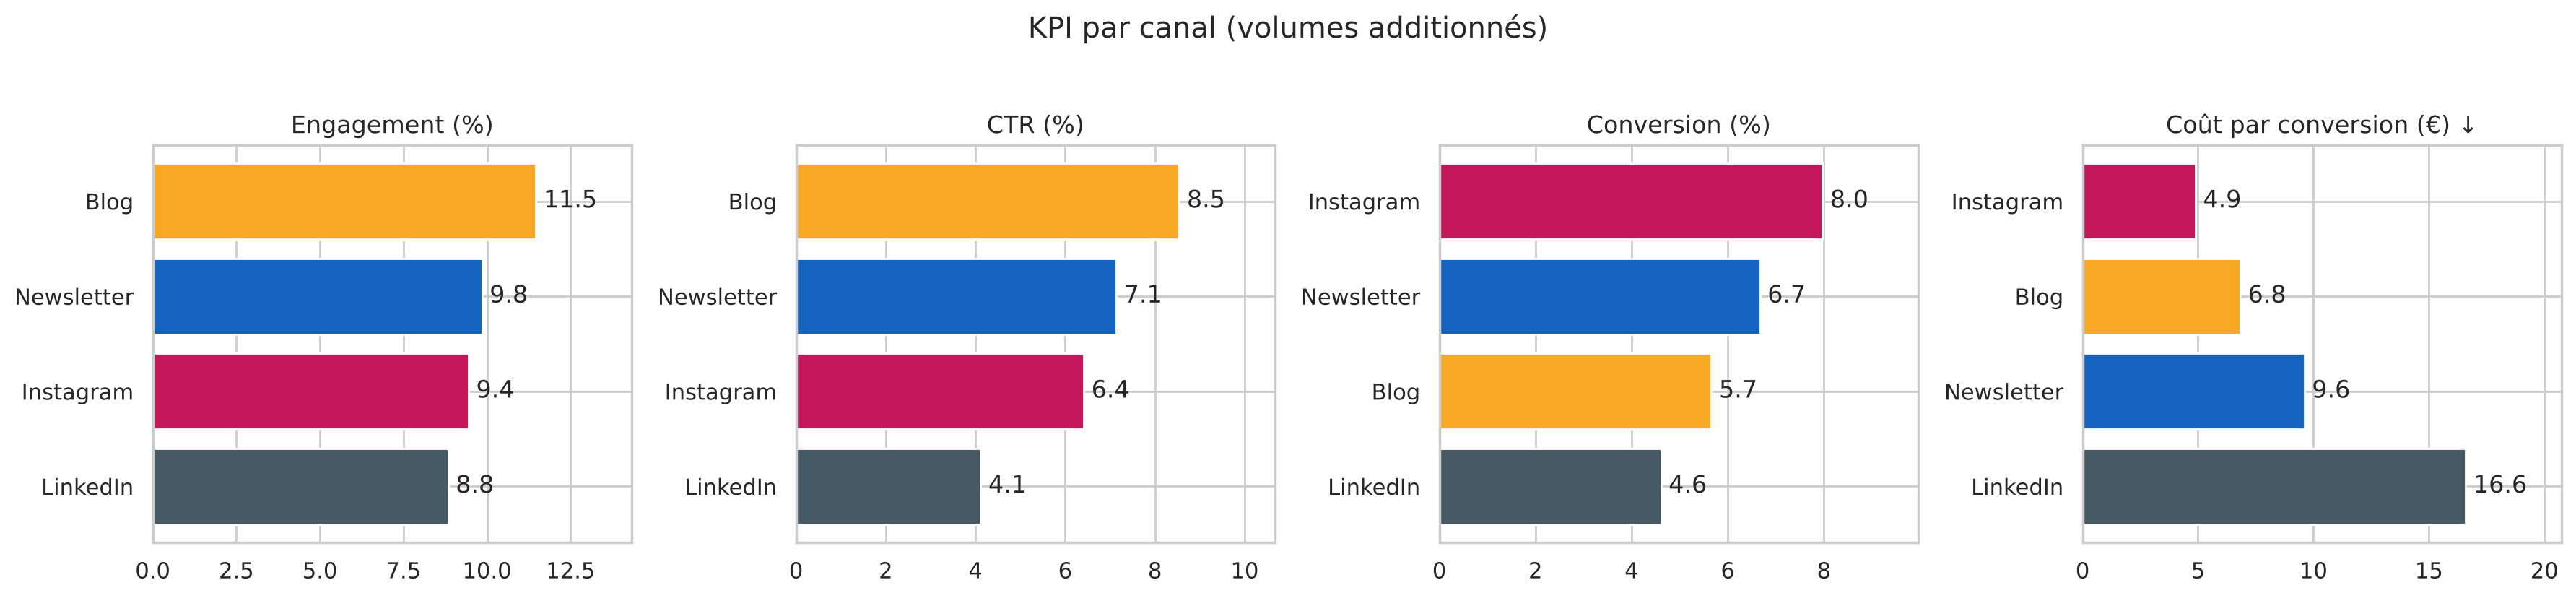

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, titre in zip(axes, ['taux_engagement_pct', 'ctr_pct', 'taux_conversion_pct', 'cpl_eur'],
                          ['Engagement (%)', 'CTR (%)', 'Conversion (%)', 'Coût par conversion (€) ↓']):
    d = par_canal[col].sort_values(ascending=(col != 'cpl_eur'))
    ax.barh(d.index, d.values, color=[COUL_CANAL[c] for c in d.index])
    for i, v in enumerate(d.values):
        ax.text(v, i, f' {v:.1f}', va='center')
    ax.set_title(titre); ax.set_xlim(0, d.max() * 1.25)
plt.suptitle('KPI par canal (volumes additionnés)', y=1.03)
plt.tight_layout(); plt.show()

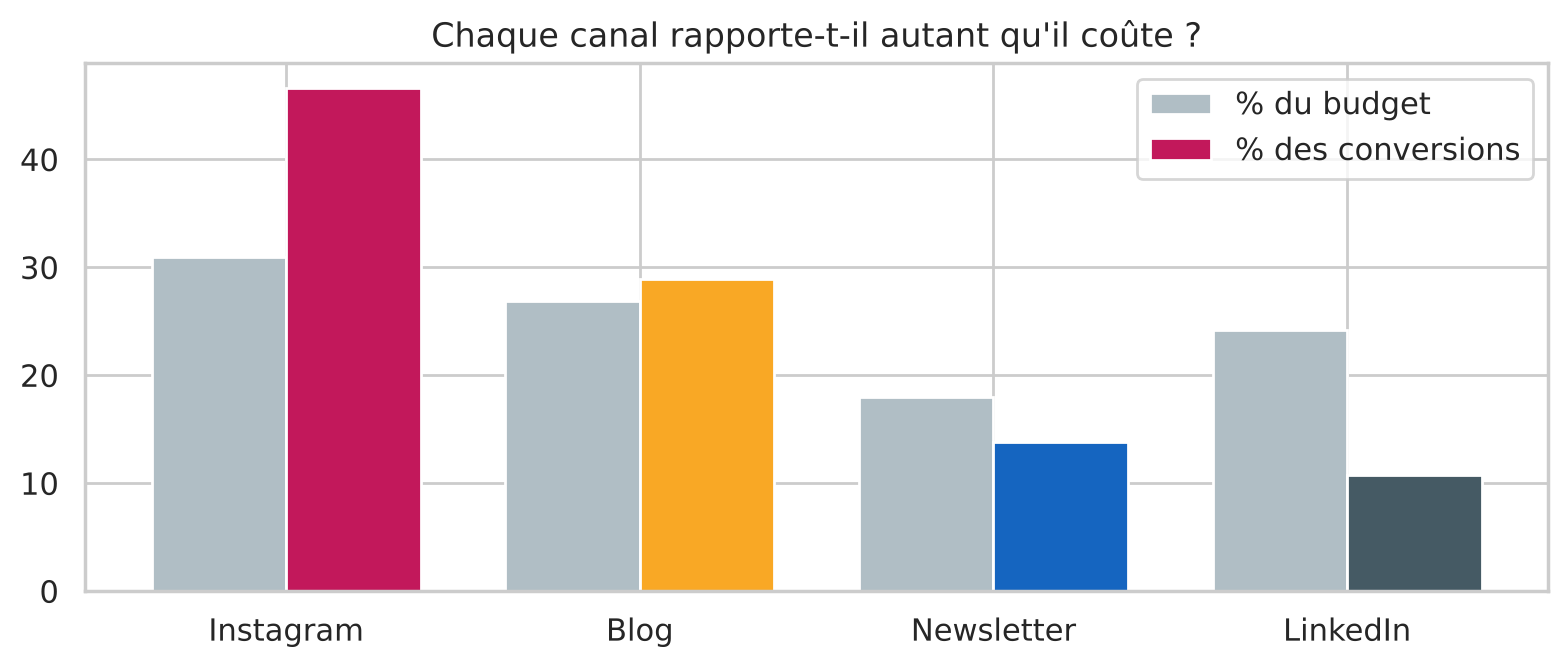

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(par_canal)); w = 0.38
ax.bar(x - w/2, par_canal['part_budget_%'], w, label='% du budget', color='#B0BEC5')
ax.bar(x + w/2, par_canal['part_conversions_%'], w, label='% des conversions', color=[COUL_CANAL[c] for c in par_canal.index])
ax.set_xticks(x); ax.set_xticklabels(par_canal.index); ax.legend()
ax.set_title('Chaque canal rapporte-t-il autant qu\'il coûte ?')
plt.tight_layout(); plt.show()

**Constat :**
- **Instagram est le canal le plus rentable.** Il a le coût par conversion le plus bas (environ 4,90 €) et le meilleur taux de conversion (environ 8 %). Il apporte **47 % des conversions pour 31 % du budget**.
- **Le Blog a le meilleur CTR (8,5 %) et le meilleur engagement (11,5 %).** Il attire et fait cliquer, avec un coût par conversion correct (environ 6,80 €).
- **La Newsletter est dans la moyenne** : CTR de 7,1 %, coût par conversion d'environ 9,60 €.
- **LinkedIn est nettement le moins efficace** : coût par conversion d'environ 16,60 €, soit plus de 3 fois celui d'Instagram, et CTR de 4,1 %. Il consomme 24 % du budget pour 11 % des conversions. C'est cohérent pour une marque beauté grand public : LinkedIn touche surtout un public professionnel.

## 5. Comparaison par format

In [8]:
par_format = contenus.groupby('content_type').apply(kpi, include_groups=False)
par_format['part_conversions_%'] = par_format['conversions'] / par_format['conversions'].sum() * 100
par_format.sort_values('cpl_eur').round(2)

,nb_contenus,portee,conversions,cout_eur,taux_engagement_pct,ctr_pct,taux_conversion_pct,cpl_eur,part_conversions_%
content_type,,,,,,,,,
storytelling,14.0,273536.0,1368.0,6010.80,9.59,7.59,6.59,4.39,49.96
education,10.0,155387.0,525.0,3822.30,11.93,5.23,6.46,7.28,19.17
product,9.0,102625.0,420.0,4501.59,8.67,6.04,6.78,10.72,15.34
promotion,12.0,115805.0,425.0,5799.45,8.77,5.98,6.13,13.65,15.52


**Constat :**
- **Le storytelling est le format le plus rentable** : coût par conversion d'environ 4,40 €, et **la moitié des conversions** (environ 50 %).
- **Le contenu éducatif suscite le plus d'engagement** (11,9 %). Il fait réagir et installe l'expertise, avec un coût par conversion correct (environ 7,30 €).
- **La promotion est le format le plus cher** : environ 13,70 € par conversion, plus de 3 fois le storytelling. Les promotions directes convertissent mal, ou attirent des clients qui auraient acheté de toute façon.

## 6. Croisement canal × format

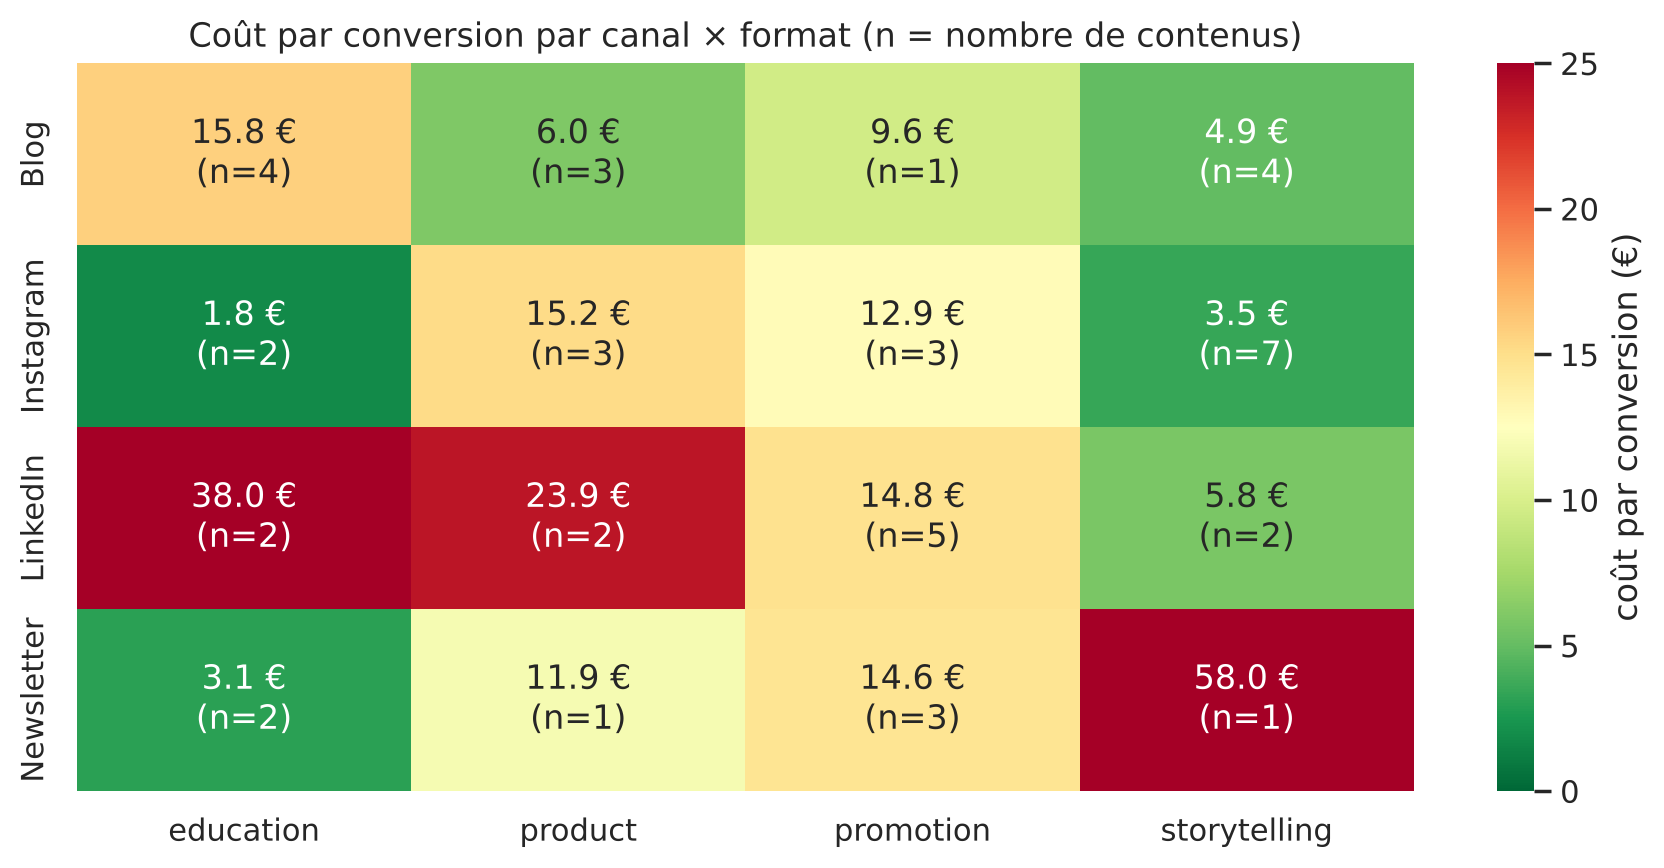

In [9]:
croise = contenus.groupby(['channel', 'content_type']).apply(kpi, include_groups=False)
cpl = croise['cpl_eur'].unstack()
n = croise['nb_contenus'].unstack()
annot = cpl.round(1).astype(str) + ' €\n(n=' + n.astype(int).astype(str) + ')'

plt.figure(figsize=(9, 4.5))
sns.heatmap(cpl, annot=annot, fmt='', cmap='RdYlGn_r', vmin=0, vmax=25,
            cbar_kws={'label': 'coût par conversion (€)'})
plt.title('Coût par conversion par canal × format (n = nombre de contenus)')
plt.xlabel(''); plt.ylabel('')
plt.tight_layout(); plt.show()

**Constat :**
- **Instagram × storytelling est la combinaison la plus solide** : environ 3,50 € par conversion sur **7 contenus**, la case la mieux renseignée.
- **Blog × storytelling** (environ 4,90 € sur 4 contenus) est aussi fiable.
- **Les cases très vertes ou très rouges avec 1 ou 2 contenus ne prouvent rien.** Par exemple Newsletter × storytelling, à 58 € sur un seul post, ou Instagram × éducation, à 1,80 € sur 2 posts.
- **Sur LinkedIn, tous les formats sauf le storytelling coûtent plus de 14 € par conversion.**

## 7. Meilleurs et moins bons contenus

In [10]:
cols = ['content_id', 'publication_date', 'channel', 'content_type', 'reach', 'ctr_pct', 'taux_conversion_pct', 'cpl_eur']
print('Top 5 (coût par conversion le plus bas)')
display(contenus.sort_values('cpl_eur')[cols].head(5).round(2))
print('Flop 5 (coût par conversion le plus élevé)')
display(contenus.sort_values('cpl_eur')[cols].tail(5).round(2))

Top 5 (coût par conversion le plus bas)


,content_id,publication_date,channel,content_type,reach,ctr_pct,taux_conversion_pct,cpl_eur
5,POST006,2025-02-10,Instagram,education,27666,9.11,7.90,0.42
42,POST043,2025-12-03,Instagram,storytelling,23686,10.18,9.58,0.95
8,POST009,2025-03-06,Instagram,storytelling,27444,7.57,8.66,1.41
12,POST013,2025-04-07,Instagram,storytelling,28668,10.90,9.72,1.75
18,POST019,2025-05-25,Blog,product,12696,10.64,5.33,1.83


Flop 5 (coût par conversion le plus élevé)


,content_id,publication_date,channel,content_type,reach,ctr_pct,taux_conversion_pct,cpl_eur
26,POST027,2025-07-28,Newsletter,storytelling,6961,1.64,7.02,58.02
16,POST017,2025-05-09,Blog,education,2737,2.19,6.67,71.64
38,POST039,2025-11-01,Instagram,product,1800,9.33,3.57,102.60
23,POST024,2025-07-04,Blog,education,1313,11.12,4.79,108.11
40,POST041,2025-11-17,LinkedIn,education,5815,7.67,1.35,110.63


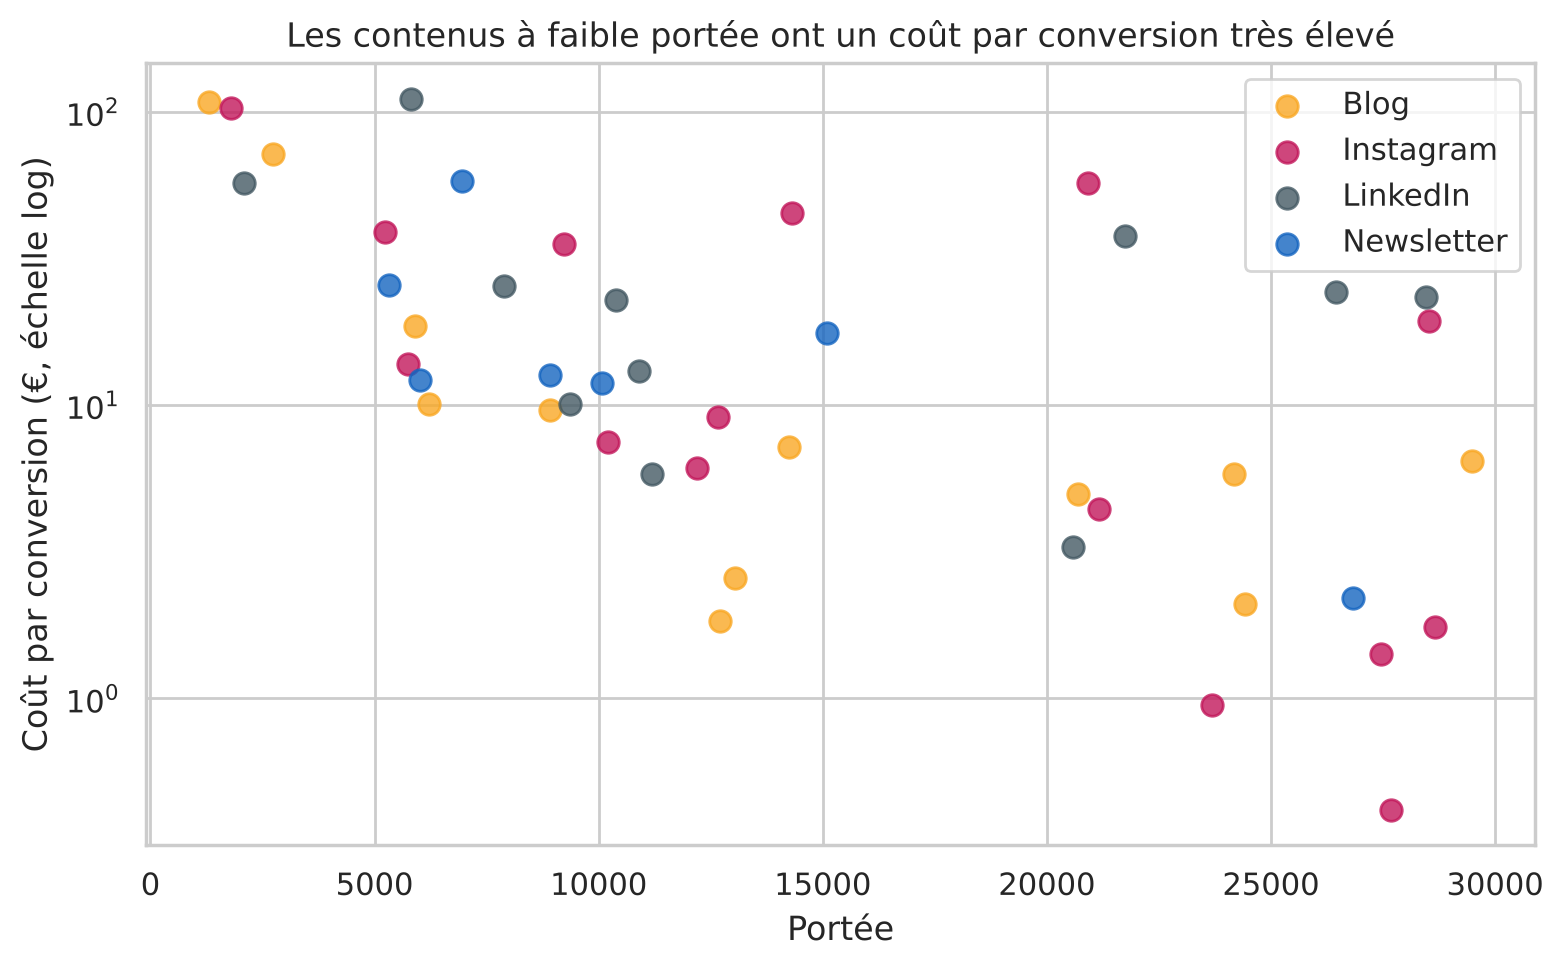

Corrélation de rang (Spearman) portée / coût par conversion : -0.60


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for canal, g in contenus.groupby('channel'):
    ax.scatter(g['reach'], g['cpl_eur'], s=60, alpha=0.8, label=canal, color=COUL_CANAL[canal])
ax.set_yscale('log'); ax.set_xlabel('Portée'); ax.set_ylabel('Coût par conversion (€, échelle log)')
ax.set_title('Les contenus à faible portée ont un coût par conversion très élevé')
ax.legend(); plt.tight_layout(); plt.show()
print(f"Corrélation de rang (Spearman) portée / coût par conversion : "
      f"{contenus[['reach', 'cpl_eur']].corr(method='spearman').iloc[0, 1]:.2f}")

**Constat :**
- Les 5 contenus les plus chers ont tous une **très faible portée** (moins de 7 000 personnes) : leur coût de production est réparti sur trop peu de conversions.
- Les meilleurs sont des posts **Instagram storytelling ou éducation** à forte portée (plus de 23 000 personnes).

## 8. Corrélation n'est pas causalité
Le graphique précédent montre que **la portée explique une grande partie du coût par conversion** (corrélation de −0,60). Plusieurs facteurs peuvent donc fausser la comparaison entre canaux et formats :

| Facteur de confusion | Exemple |
|---|---|
| **Portée / budget de diffusion** | Instagram storytelling a souvent eu une forte portée : est-ce le format qui convertit, ou la diffusion qui était plus large ? |
| **Saisonnalité** | Un post publié en décembre (cadeaux) convertit plus qu'en août, quel que soit son format |
| **Sujet et produit mis en avant** | Un storytelling sur un best-seller convertit mieux qu'un post produit sur une niche |
| **Audience du canal** | Les abonnés de la newsletter sont déjà clients : ils convertissent plus facilement |
| **Attribution** | Une conversion attribuée à un post a pu être déclenchée par un autre point de contact |
| **Petits effectifs** | 1 à 7 contenus par case : une différence peut venir du hasard |

**On peut donc dire :** « les contenus Instagram storytelling sont **associés** au coût par conversion le plus bas ».
**On ne peut pas dire :** « passer au storytelling **fera baisser** le coût par conversion ».

**Pour le démontrer, il faut un test A/B :**
1. Même produit, même période, même budget de diffusion et même audience, découpée au hasard en deux groupes.
2. Version A en storytelling, version B en promotion.
3. On mesure le coût par conversion de chaque version sur au moins 2 semaines, puis on teste si l'écart est significatif.

## 9. Scénario de réallocation du budget
**Hypothèse simplificatrice :** chaque combinaison canal × format garde son coût par conversion actuel quand on y ajoute du budget. Dans la réalité, le rendement baisse quand on augmente les dépenses : ce scénario est donc **un maximum optimiste**, à valider par des tests.

**Scénario :** on retire **la moitié du budget LinkedIn** et **la moitié du budget promotion des autres canaux**, et on le réinvestit dans **Instagram storytelling** et **Blog storytelling**, à parts égales.

In [12]:
budget = croise['cout_eur'].copy()
cpl_actuel = croise['cpl_eur']
nouveau = budget.copy()

retire = 0.0
for (canal, fmt), montant in budget.items():
    if canal == 'LinkedIn' or fmt == 'promotion':
        retire += montant * 0.5
        nouveau[(canal, fmt)] = montant * 0.5
nouveau[('Instagram', 'storytelling')] += retire / 2
nouveau[('Blog', 'storytelling')] += retire / 2

conv_actuelles = (budget / cpl_actuel).sum()
conv_scenario = (nouveau / cpl_actuel).sum()
clics_actuels = contenus['clicks'].sum()

scenario = pd.DataFrame({
    'actuel': {'budget_eur': budget.sum(), 'conversions': conv_actuelles, 'cpl_eur': budget.sum() / conv_actuelles},
    'scénario': {'budget_eur': nouveau.sum(), 'conversions': conv_scenario, 'cpl_eur': nouveau.sum() / conv_scenario},
}).T.round(2)
print(f'Budget déplacé : {retire:,.0f} €'.replace(',', ' '))
scenario

Budget déplacé : 4 309 €


,budget_eur,conversions,cpl_eur
actuel,20134.14,2738.00,7.35
scénario,20134.14,3500.88,5.75


**Lecture :**
- **À budget constant**, ce scénario ferait passer le coût par conversion d'environ 7,35 € à **moins de 6 €**, ce qui dépasse l'objectif O3 de 6,50 €.
- **C'est un plafond théorique.** On le valide **progressivement**, en déplaçant 20 à 30 % du budget par vague et en mesurant le résultat à chaque étape, au lieu de tout basculer d'un coup.

## 10. Recommandations pour le calendrier éditorial
| Décision | Constat qui la justifie | KPI de suivi |
|---|---|---|
| **Instagram storytelling = format pivot** (3 à 4 posts par semaine) | Coût par conversion le plus bas, case la plus fiable (7 posts) | Coût par conversion, taux de conversion |
| **Blog storytelling et produit** (1 article par semaine) | Meilleur CTR, coût par conversion correct ; bon support pour le SEO et les recommandations (mission 6) | CTR, conversions |
| **Contenu éducatif** pour l'engagement (conseils, routines) | Meilleur engagement, nourrit la relation | Taux d'engagement |
| **Newsletter** : 1 envoi par semaine, éditorial et segmenté selon la mission 6 | Audience déjà cliente, CTR de 7,1 % | CTR, conversions, désinscriptions |
| **Promotions limitées** et ciblées (segments sensibles au prix, rétention P2) | Coût par conversion le plus élevé (13,70 €) | Coût par conversion, marge |
| **LinkedIn réduit à 1 post par semaine**, angle marque et coulisses (qualité, engagement, recrutement) | Coût par conversion 3 fois plus élevé ; ce n'est pas un canal de vente pour la beauté grand public | Engagement, notoriété (pas les conversions) |
| **Test A/B** storytelling vs promotion sur Instagram | Prouver la causalité (étape 8) | Écart de coût par conversion |

## 11. Export de `content_kpis.csv`

In [13]:
export = contenus[['content_id', 'publication_date', 'channel', 'content_type', 'reach', 'clicks', 'interactions',
                   'conversions', 'cost_eur', 'taux_engagement_pct', 'ctr_pct', 'taux_conversion_pct', 'cpl_eur']].round(2)
export.to_csv(os.path.join(OUT, 'content_kpis.csv'), index=False)

synthese = pd.concat([
    par_canal.assign(niveau='canal').reset_index().rename(columns={'channel': 'groupe'}),
    par_format.assign(niveau='format').reset_index().rename(columns={'content_type': 'groupe'}),
    global_kpi.to_frame().T.assign(niveau='global', groupe='Tous les contenus'),
], ignore_index=True)[['niveau', 'groupe', 'nb_contenus', 'portee', 'conversions', 'cout_eur',
                       'taux_engagement_pct', 'ctr_pct', 'taux_conversion_pct', 'cpl_eur']].round(2)
synthese.to_csv(os.path.join(OUT, 'content_kpis_summary.csv'), index=False)
print('content_kpis.csv :', export.shape, '| content_kpis_summary.csv :', synthese.shape)
synthese

content_kpis.csv : (45, 13) | content_kpis_summary.csv : (9, 10)


,niveau,groupe,nb_contenus,portee,conversions,cout_eur,taux_engagement_pct,ctr_pct,taux_conversion_pct,cpl_eur
0,canal,Instagram,15.0,249450.0,1275.0,6227.50,9.44,6.41,7.97,4.88
1,canal,Blog,12.0,163850.0,792.0,5407.80,11.46,8.54,5.66,6.83
2,canal,Newsletter,7.0,79202.0,377.0,3620.18,9.85,7.14,6.67,9.60
3,canal,LinkedIn,11.0,154851.0,294.0,4878.66,8.84,4.12,4.61,16.59
4,format,education,10.0,155387.0,525.0,3822.30,11.93,5.23,6.46,7.28
5,format,product,9.0,102625.0,420.0,4501.59,8.67,6.04,6.78,10.72
6,format,promotion,12.0,115805.0,425.0,5799.45,8.77,5.98,6.13,13.65
7,format,storytelling,14.0,273536.0,1368.0,6010.80,9.59,7.59,6.59,4.39
8,global,Tous les contenus,45.0,647353.0,2738.0,20134.14,9.86,6.49,6.52,7.35


**Fichiers produits dans `outputs/` :**
- `content_kpis.csv` : les 4 KPI de chacun des 45 contenus (livrable attendu) ;
- `content_kpis_summary.csv` : les KPI agrégés par canal, par format et au global.